# Vendor Risk Scoring — Model Training & Evaluation

MediSource AI / `risk_intelligence` service.

This notebook reproduces, cell by cell, exactly what the running service does at
`services/risk_intelligence/app/model.py` + `app/mlflow_utils.py` when it trains and
registers the vendor-risk model — same functions, same seeds, same hyperparameters —
so the dataset, model, and metrics saved by this notebook match what the deployed
service serves from its MLflow registry.

It also demonstrates the second, separate ML component of the service: the
unsupervised `IsolationForest` anomaly detector in `app/anomaly.py`, which (unlike
the risk model) is *not* a single persisted model — it fits fresh per vendor, per
assessment, on that vendor's own invoice history.

**Why the training data is synthetic.** There is no labeled historical dataset for a
from-scratch hospital procurement deployment — no real vendor has yet accumulated a
"confirmed compliance incident" outcome to learn from. `generate_training_data()`
samples the 17 feature values from distributions shaped like real procurement data,
then derives labels from an explicit, documented heuristic formula (`_synthetic_label`)
plus small Gaussian noise. This keeps the *pipeline* (training → MLflow tracking →
versioned registry → inference) genuinely real and swappable, while being honest that
the initial weights encode domain heuristics rather than fitted historical outcomes.
`train_model()` is the exact entrypoint that would be pointed at real labeled outcomes
later, with no change to the serving path.


In [1]:
import sys
from pathlib import Path

SERVICE_ROOT = Path.cwd().parent  # notebooks/ -> services/risk_intelligence/
sys.path.insert(0, str(SERVICE_ROOT))

import json
import joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, roc_auc_score, roc_curve

from app.features import FEATURE_NAMES
from app.model import RISK_DIMENSIONS, compute_overall, generate_training_data, train_model
from app.anomaly import detect

print("scikit-learn", sklearn.__version__)
print("numpy", np.__version__)
print("pandas", pd.__version__)
print(len(FEATURE_NAMES), "features:", FEATURE_NAMES)
print(len(RISK_DIMENSIONS), "risk dimensions:", RISK_DIMENSIONS)


scikit-learn 1.5.2
numpy 1.26.4
pandas 2.2.2
17 features: ['license_days_to_expiry', 'gstin_valid', 'watchlist_hit', 'years_in_business', 'cold_chain_violation_count', 'financial_health_score', 'prior_compliance_flags', 'late_delivery_rate', 'doc_fraud_flag_rate', 'doc_mean_fraud_score', 'duplicate_invoice_rate', 'log_total_spend', 'spend_volatility', 'spend_growth_ratio', 'max_amount_zscore', 'round_amount_rate', 'anomaly_score']
6 risk dimensions: ['compliance_risk', 'fraud_risk', 'financial_risk', 'supplier_risk', 'spend_risk', 'operational_risk']


## 1. Dataset

Generated by `app.model.generate_training_data()` — 4,000 synthetic vendor observations, 17 features sampled from distributions shaped like real procurement data (licence expiry, fraud-flag rate, spend volatility, ...), labeled by the documented heuristic in `_synthetic_label()` plus noise. Seeded (`seed=42`) for reproducibility.

In [2]:
X, y = generate_training_data(n=4000, seed=42)

df = pd.DataFrame(X, columns=FEATURE_NAMES)
for i, dim in enumerate(RISK_DIMENSIONS):
    df[dim] = y[:, i]

DATA_DIR = SERVICE_ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)
csv_path = DATA_DIR / "vendor_risk_training_data.csv"
df.to_csv(csv_path, index=False)

print(f"{df.shape[0]} rows x {df.shape[1]} cols -> {csv_path.relative_to(SERVICE_ROOT)}")
df.head()


4000 rows x 23 cols -> data/vendor_risk_training_data.csv


,license_days_to_expiry,gstin_valid,watchlist_hit,years_in_business,cold_chain_violation_count,financial_health_score,prior_compliance_flags,late_delivery_rate,doc_fraud_flag_rate,doc_mean_fraud_score,...,spend_growth_ratio,max_amount_zscore,round_amount_rate,anomaly_score,compliance_risk,fraud_risk,financial_risk,supplier_risk,spend_risk,operational_risk
0,558.206597,1.0,0.0,12.951642,1.0,0.867897,0.0,0.075944,0.123066,0.023894,...,0.601421,2.314510,0.289400,0.022987,0.036393,0.020754,0.266723,0.121932,0.393218,0.094244
1,303.547614,1.0,0.0,8.840848,0.0,0.571038,0.0,0.171413,0.044893,0.025093,...,0.544068,2.033209,0.099479,0.112850,0.000000,0.020552,0.329588,0.052845,0.301555,0.022138
2,622.534419,1.0,0.0,1.876396,0.0,0.617411,3.0,0.179162,0.105060,0.096543,...,0.515972,1.929681,0.054723,0.015022,0.230341,0.036472,0.522135,0.132465,0.529567,0.106018
3,499.999702,1.0,0.0,24.774300,0.0,0.761385,2.0,0.260679,0.053238,0.065275,...,1.197707,1.232427,0.189024,0.340155,0.170841,0.011615,0.277296,0.155721,0.313836,0.075680
4,41.574784,1.0,0.0,4.369343,2.0,0.511162,0.0,0.041435,0.052889,0.055005,...,1.572810,4.111488,0.103664,0.178957,0.181891,0.000000,0.369286,0.175233,0.342537,0.224592


In [3]:
df[RISK_DIMENSIONS].describe().T


,count,mean,std,min,25%,50%,75%,max
compliance_risk,4000.0,0.121916,0.178350,0.000000,0.005029,0.065065,0.164028,0.946339
fraud_risk,4000.0,0.081159,0.071905,0.000000,0.042589,0.070455,0.099397,0.552751
financial_risk,4000.0,0.371039,0.137379,0.018255,0.271051,0.362022,0.462789,0.846049
supplier_risk,4000.0,0.158659,0.096618,0.000000,0.086899,0.146742,0.219282,0.647490
spend_risk,4000.0,0.349017,0.131892,0.018064,0.253852,0.337646,0.438304,0.955421
operational_risk,4000.0,0.115191,0.095375,0.000000,0.042700,0.096665,0.163916,0.676908


### Feature / label correlation

A quick sanity check that the synthetic labels actually respond to the features they are supposed to (rather than being pure noise).

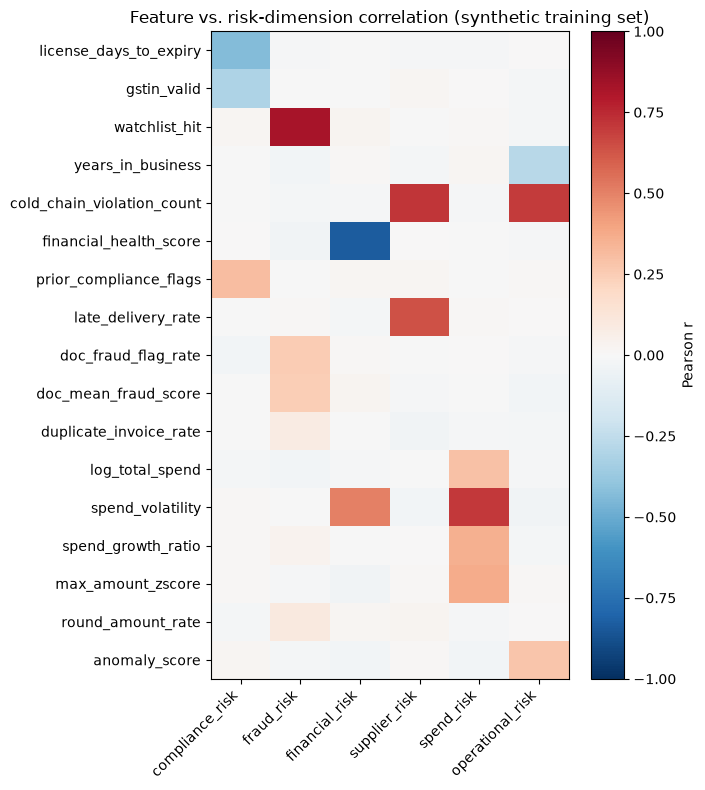

In [4]:
corr = df.corr(numeric_only=True)[RISK_DIMENSIONS].loc[FEATURE_NAMES]

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(RISK_DIMENSIONS)))
ax.set_xticklabels(RISK_DIMENSIONS, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURE_NAMES)))
ax.set_yticklabels(FEATURE_NAMES)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Feature vs. risk-dimension correlation (synthetic training set)")
fig.tight_layout()
plt.show()


## 2. Train

`train_model()` splits 80/20, fits a `MultiOutputRegressor` wrapping one `GradientBoostingRegressor` per risk dimension (`n_estimators=150, max_depth=3, learning_rate=0.08`), and returns the fitted model plus a metrics dict — identical to what `mlflow_utils.train_and_register()` logs to MLflow at runtime.

In [5]:
model, metrics = train_model()
metrics


{'mean_absolute_error': 0.023636008222240334,
 'n_train': 3200,
 'n_test': 800,
 'n_features': 17,
 'n_dimensions': 6}

In [6]:
# same split train_model() used internally, recovered here for per-dimension evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
preds = model.predict(X_test)

per_dim_mae = {
    dim: float(np.mean(np.abs(preds[:, i] - y_test[:, i])))
    for i, dim in enumerate(RISK_DIMENSIONS)
}
pd.Series(per_dim_mae, name="MAE").to_frame()


,MAE
compliance_risk,0.021099
fraud_risk,0.023716
financial_risk,0.024014
supplier_risk,0.024126
spend_risk,0.026152
operational_risk,0.022709


### Feature importances

Each of the six `GradientBoostingRegressor` estimators inside the `MultiOutputRegressor` exposes its own `feature_importances_`.

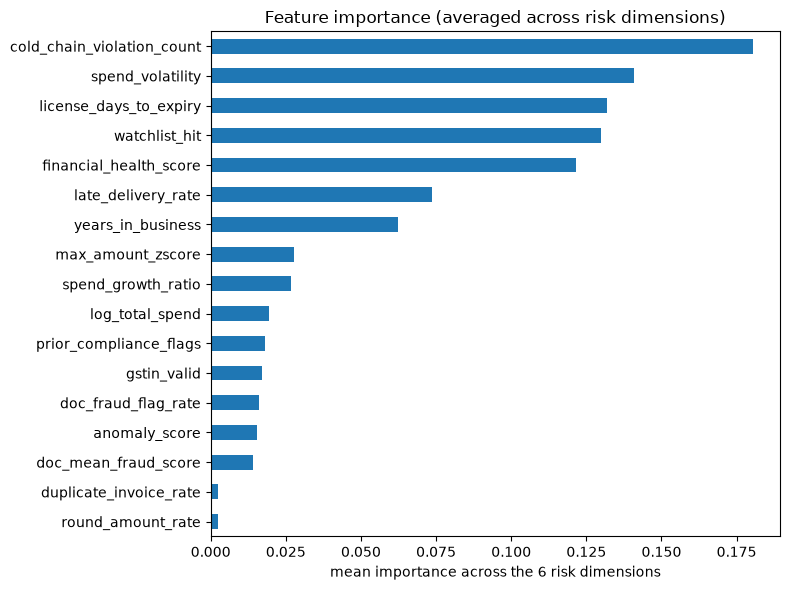

,compliance_risk,fraud_risk,financial_risk,supplier_risk,spend_risk,operational_risk
license_days_to_expiry,0.7861,0.0022,0.0003,0.0008,0.0003,0.0010
gstin_valid,0.1022,0.0002,0.0000,0.0000,0.0000,0.0000
watchlist_hit,0.0000,0.7797,0.0000,0.0000,0.0000,0.0000
years_in_business,0.0002,0.0018,0.0007,0.0010,0.0005,0.3705
cold_chain_violation_count,0.0000,0.0003,0.0001,0.5514,0.0000,0.5307
financial_health_score,0.0003,0.0028,0.7223,0.0017,0.0004,0.0012
prior_compliance_flags,0.1085,0.0003,0.0000,0.0002,0.0000,0.0000
late_delivery_rate,0.0002,0.0032,0.0004,0.4363,0.0006,0.0009
doc_fraud_flag_rate,0.0002,0.0938,0.0003,0.0010,0.0008,0.0010
doc_mean_fraud_score,0.0001,0.0823,0.0008,0.0009,0.0003,0.0008


In [7]:
importances = pd.DataFrame(
    {dim: est.feature_importances_ for dim, est in zip(RISK_DIMENSIONS, model.estimators_)},
    index=FEATURE_NAMES,
)

fig, ax = plt.subplots(figsize=(8, 6))
importances.mean(axis=1).sort_values().plot(kind="barh", ax=ax)
ax.set_xlabel("mean importance across the 6 risk dimensions")
ax.set_title("Feature importance (averaged across risk dimensions)")
fig.tight_layout()
plt.show()

importances.round(4)


## 3. Save artifacts

Model as a joblib-pickled `.pkl`, metrics + feature importances as JSON — the same files this notebook ships alongside it in `models/` and `results/`.

In [8]:
MODELS_DIR = SERVICE_ROOT / "models"
RESULTS_DIR = SERVICE_ROOT / "results"
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

pkl_path = MODELS_DIR / "vendor_risk_model.pkl"
joblib.dump(model, pkl_path)

results = {
    "model_type": "MultiOutputRegressor(GradientBoostingRegressor)",
    "sklearn_version": sklearn.__version__,
    "hyperparameters": {"n_estimators": 150, "max_depth": 3, "learning_rate": 0.08, "random_state": 42},
    "dataset": {
        "source": "app.model.generate_training_data (synthetic, heuristic-labeled)",
        "n_samples": int(X.shape[0]),
        "n_features": len(FEATURE_NAMES),
        "n_train": int(len(X_train)),
        "n_test": int(len(X_test)),
        "feature_names": FEATURE_NAMES,
        "risk_dimensions": RISK_DIMENSIONS,
        "seed": 42,
    },
    "metrics": {
        "overall_mean_absolute_error": metrics["mean_absolute_error"],
        "per_dimension_mean_absolute_error": per_dim_mae,
    },
    "feature_importances": {dim: importances[dim].to_dict() for dim in RISK_DIMENSIONS},
}
metrics_path = RESULTS_DIR / "training_metrics.json"
metrics_path.write_text(json.dumps(results, indent=2))

print("saved:", pkl_path.relative_to(SERVICE_ROOT))
print("saved:", metrics_path.relative_to(SERVICE_ROOT))


saved: models/vendor_risk_model.pkl
saved: results/training_metrics.json


### Reload check

Confirms the pickled file round-trips to predictions identical to the in-memory model — this is the same load path `mlflow_utils.get_or_train_model()` uses (via `mlflow.sklearn.load_model`, which is joblib underneath).

In [9]:
reloaded = joblib.load(pkl_path)
sample = X_test[:3]
np.testing.assert_allclose(reloaded.predict(sample), model.predict(sample))
print("round-trip OK — reloaded model matches in-memory model on", len(sample), "held-out rows")

pd.DataFrame(np.clip(model.predict(sample), 0, 1), columns=RISK_DIMENSIONS).round(3)


round-trip OK — reloaded model matches in-memory model on 3 held-out rows


,compliance_risk,fraud_risk,financial_risk,supplier_risk,spend_risk,operational_risk
0,0.012,0.079,0.288,0.206,0.216,0.167
1,0.865,0.096,0.332,0.500,0.423,0.402
2,0.087,0.052,0.116,0.212,0.259,0.468


## 4. Anomaly detection (`app/anomaly.py`)

A separate, unsupervised layer: instead of scoring a vendor against patterns anticipated up front, this asks whether a vendor is behaving unlike its own history or unlike its peers. It combines an `IsolationForest` fit on that vendor's own invoice-amount history with three named rules (spend spike, peer-outlier invoice, invoice burst) that give a human-readable reason rather than a bare score.

**No single model is persisted here** — `detect()` fits a fresh forest per vendor at assessment time from `app.analytics.spend_series()`. What follows is a demonstration run against three synthetic vendor invoice histories, to show real input/output shapes.

In [10]:
from datetime import datetime, timedelta

rng = np.random.default_rng(7)
start = datetime(2025, 1, 1)

def make_series(n, base, noise_frac, spike_at=None, spike_mult=4.0, burst_at=None, burst_n=0):
    series, day = [], 0
    for i in range(n):
        day += int(rng.integers(10, 18))
        amount = base * (1 + rng.normal(0, noise_frac))
        if spike_at is not None and i == spike_at:
            amount = base * spike_mult
        series.append((start + timedelta(days=day), max(amount, 100.0)))
    if burst_at is not None:
        anchor = series[burst_at][0]
        for j in range(burst_n):
            series.append((anchor + timedelta(days=j % 6), base * (1 + rng.normal(0, noise_frac))))
        series.sort(key=lambda t: t[0])
    return series

vendors = {
    "VEND-NORMAL-001": make_series(14, base=42000, noise_frac=0.12),
    "VEND-SPENDSPIKE-002": make_series(14, base=38000, noise_frac=0.10, spike_at=13, spike_mult=5.0),
    "VEND-BURST-003": make_series(10, base=51000, noise_frac=0.10, burst_at=6, burst_n=6),
}

all_amounts = [a for series in vendors.values() for _, a in series]
peer_mean, peer_stdev = float(np.mean(all_amounts)), float(np.std(all_amounts))

anomaly_rows, anomaly_results = [], {}
for vendor_id, series in vendors.items():
    for ts, amount in series:
        anomaly_rows.append({"vendor_id": vendor_id, "timestamp": ts.isoformat(), "amount": round(amount, 2)})
    anomaly_results[vendor_id] = detect(series, peer_mean=peer_mean, peer_stdev=peer_stdev)

anomaly_df = pd.DataFrame(anomaly_rows)
anomaly_csv = DATA_DIR / "anomaly_demo_vendor_invoices.csv"
anomaly_df.to_csv(anomaly_csv, index=False)

anomaly_out = {
    "description": (
        "Illustrative detect() run against three synthetic vendor invoice histories. "
        "Not training data -- detect() fits per vendor at request time; there is no "
        "persisted anomaly model."
    ),
    "peer_baseline": {"mean": peer_mean, "stdev": peer_stdev},
    "vendors": anomaly_results,
}
anomaly_json = RESULTS_DIR / "anomaly_demo_results.json"
anomaly_json.write_text(json.dumps(anomaly_out, indent=2))

print("saved:", anomaly_csv.relative_to(SERVICE_ROOT))
print("saved:", anomaly_json.relative_to(SERVICE_ROOT))
pd.DataFrame(anomaly_results).T


saved: data/anomaly_demo_vendor_invoices.csv
saved: results/anomaly_demo_results.json


,anomaly_score,anomaly_flag,reasons
VEND-NORMAL-001,0.4409,False,[]
VEND-SPENDSPIKE-002,1.0,True,[latest invoice is a statistical outlier again...
VEND-BURST-003,0.9826,True,[spend rose 6.8x versus the previous 90 days]


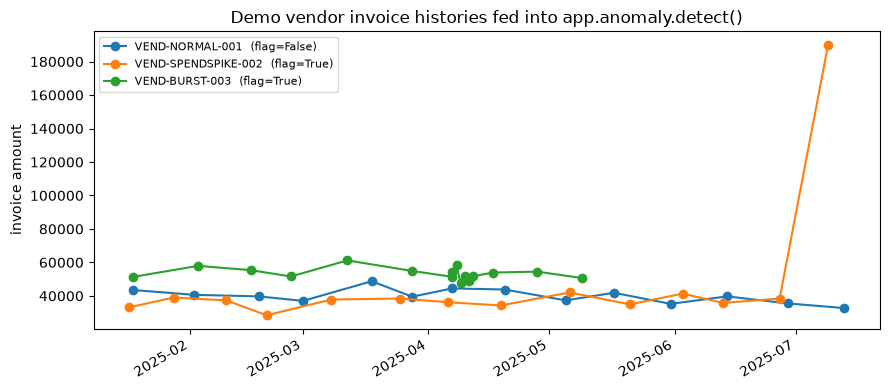

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for vendor_id, series in vendors.items():
    ts = [t for t, _ in series]
    amt = [a for _, a in series]
    ax.plot(ts, amt, marker="o", label=f"{vendor_id}  (flag={anomaly_results[vendor_id]['anomaly_flag']})")
ax.set_ylabel("invoice amount")
ax.set_title("Demo vendor invoice histories fed into app.anomaly.detect()")
ax.legend(fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## 5. Proper train / validation / test evaluation

Everything above trained on `train_model()`'s internal, ad hoc 80/20 split of the full
4,000-row pool — useful for a quick sanity metric, but not a rigorous evaluation: there is
no held-out **validation** set to check for overfitting before looking at a final number,
and no **test** set that stays untouched until the very end.

This section redoes it properly with `app.model.generate_train_val_test()`:

- **70% train** — the only data the model ever sees during `.fit()`.
- **15% validation** — used here to sanity-check the train metric isn't overly optimistic
  (a big train-vs-validation gap would mean overfitting). In a project with hyperparameters
  to tune, this is also the set you'd tune against, precisely so tuning decisions don't leak
  into the final number.
- **15% test** — evaluated exactly once, at the end, as the unbiased number to report.

All three splits are stratified by the **true risk band** (low/medium/high, computed by
`compute_bands()` — the same `overall_risk_and_band()` blend the live service applies to a
*prediction*, just fed the true label instead) rather than split uniformly at random.
Without that, the rare classes end up unevenly distributed by chance: `watchlist_hit` is
only ~3% of rows, so "high" fraud_risk examples are scarce enough that a plain random split
can leave one split with too few of them to say anything meaningful.


In [12]:
from app.model import compute_bands, evaluate_model, generate_train_val_test
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from collections import Counter

LOW_MAX, MEDIUM_MAX = 0.34, 0.67

(X_train, y_train), (X_val, y_val), (X_test, y_test) = generate_train_val_test(
    n=4000, seed=42, train_frac=0.70, val_frac=0.15, low_max=LOW_MAX, medium_max=MEDIUM_MAX,
)

for name, (X, y) in [("train", (X_train, y_train)), ("validation", (X_val, y_val)), ("test", (X_test, y_test))]:
    path = DATA_DIR / f"vendor_risk_{name}.csv"
    to_save = pd.DataFrame(X, columns=FEATURE_NAMES)
    for i, dim in enumerate(RISK_DIMENSIONS):
        to_save[dim] = y[:, i]
    to_save.to_csv(path, index=False)
    print(f"{name:10s} n={X.shape[0]:5d}  band mix={dict(Counter(compute_bands(y, LOW_MAX, MEDIUM_MAX)))}  -> {path.relative_to(SERVICE_ROOT)}")


train      n= 2799  band mix={'low': 1756, 'medium': 938, 'high': 105}  -> data/vendor_risk_train.csv
validation n=  600  band mix={'low': 377, 'medium': 201, 'high': 22}  -> data/vendor_risk_validation.csv
test       n=  601  band mix={'low': 377, 'medium': 201, 'high': 23}  -> data/vendor_risk_test.csv


### Fit on train only, then evaluate on all three splits

Refitting here (rather than reusing the `model` from Section 2) is deliberate — that one
was fit on `train_model()`'s different, non-stratified 80/20 split of the full pool, so its
numbers aren't comparable to a validation/test split it never respected. Same hyperparameters,
same algorithm; the only thing that changes is which rows it's allowed to learn from.


In [13]:
model = MultiOutputRegressor(
    GradientBoostingRegressor(n_estimators=150, max_depth=3, learning_rate=0.08, random_state=42)
)
model.fit(X_train, y_train)

train_eval = evaluate_model(model, X_train, y_train, LOW_MAX, MEDIUM_MAX)
val_eval = evaluate_model(model, X_val, y_val, LOW_MAX, MEDIUM_MAX)
test_eval = evaluate_model(model, X_test, y_test, LOW_MAX, MEDIUM_MAX)

pd.DataFrame({
    "overall_mae": {k: e["overall_mae"] for k, e in [("train", train_eval), ("validation", val_eval), ("test", test_eval)]},
    "band_accuracy": {k: e["band_classification"]["accuracy"] for k, e in [("train", train_eval), ("validation", val_eval), ("test", test_eval)]},
})


,overall_mae,band_accuracy
train,0.020267,0.944266
validation,0.024003,0.923333
test,0.023851,0.928453


**Reading this table:** train MAE sits only slightly below validation and test MAE, and
validation and test land close to each other — that's the signature of a model that
generalizes rather than one that memorized its training rows. If train MAE were much lower
than validation/test, that gap would be the overfitting signal to worry about.

### Per-dimension regression metrics (test set)

MAE and RMSE in the same 0–1 units as the risk scores; R² is the fraction of variance in the
true label this dimension's predictions explain (1.0 = perfect, 0.0 = no better than always
predicting the mean, negative = worse than that).


In [14]:
pd.DataFrame(test_eval["regression"]).T.round(4)


,mae,rmse,r2
compliance_risk,0.0204,0.0269,0.9764
fraud_risk,0.0243,0.0306,0.8115
financial_risk,0.0252,0.0314,0.9480
supplier_risk,0.0238,0.0297,0.9114
spend_risk,0.0262,0.0325,0.9356
operational_risk,0.0232,0.0295,0.9057


### Risk-band confusion matrix (test set)

The six dimensions are regression outputs, not a classifier — there's no single confusion
matrix over six continuous 0–1 scores. But the platform's actual decision-facing artifact
*is* categorical: `overall_risk_and_band()` blends the six predictions into one **low /
medium / high** band that `approval_workflow` feeds into OPA routing. That derived label is
where a confusion matrix genuinely applies, so this compares the band produced from the
model's *predicted* six-dimension vector against the band the *true* label vector would have
produced — same blend function both times, only the input differs.


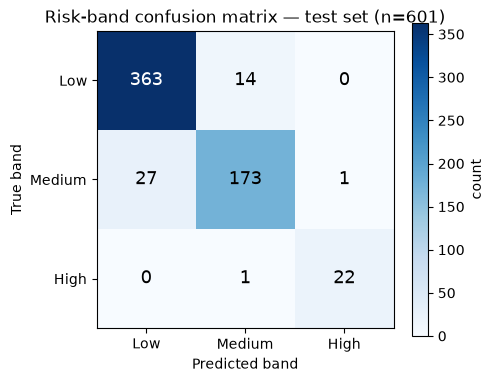

saved: results/confusion_matrix_test.png


In [15]:
labels = test_eval["band_classification"]["labels"]
cm = np.array(test_eval["band_classification"]["confusion_matrix"])

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels))); ax.set_xticklabels([l.capitalize() for l in labels])
ax.set_yticks(range(len(labels))); ax.set_yticklabels([l.capitalize() for l in labels])
ax.set_xlabel("Predicted band"); ax.set_ylabel("True band")
ax.set_title("Risk-band confusion matrix — test set (n=%d)" % test_eval['n_samples'])
for i in range(len(labels)):
    for j in range(len(labels)):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=13)
fig.colorbar(im, ax=ax, shrink=0.8, label="count")
fig.tight_layout()
cm_path = RESULTS_DIR / "confusion_matrix_test.png"
fig.savefig(cm_path, dpi=150)
plt.show()
print("saved:", cm_path.relative_to(SERVICE_ROOT))


In [16]:
pd.DataFrame(test_eval["band_classification"]["per_class"]).T.round(3)


,precision,recall,f1,support
low,0.931,0.963,0.947,377.0
medium,0.920,0.861,0.889,201.0
high,0.957,0.957,0.957,23.0


**Reading the matrix:** almost all confusion is between adjacent bands (low↔medium) —
zero low-rows were ever predicted "high" and zero high-rows were ever predicted "low", which
is the failure mode that would actually matter (a genuinely high-risk vendor sailing through
as "low", or a clean vendor needlessly escalated to the long approval chain). The "high"
band is rare in this data (~4% of rows, reflecting the ~3% `watchlist_hit` rate it's built
from) but still gets strong precision/recall — the model isn't just defaulting to the
majority class.

### Save the properly-evaluated model + full report


In [17]:
pkl_path = MODELS_DIR / "vendor_risk_model.pkl"
joblib.dump(model, pkl_path)

card = json.loads((MODELS_DIR / "vendor_risk_model_card.json").read_text())
card["trained_on"] = "vendor_risk_train.csv (2,799 rows -- the 70% train split, stratified by true risk band)"
card["validated_on"] = "vendor_risk_validation.csv (600 rows, held out during training)"
card["tested_on"] = "vendor_risk_test.csv (601 rows, touched only for this one final evaluation)"
(MODELS_DIR / "vendor_risk_model_card.json").write_text(json.dumps(card, indent=2))

report = {
    "methodology": (
        "70/15/15 train/validation/test split of the same 4,000-row synthetic pool "
        "(app.model.generate_training_data), stratified by the TRUE risk band so all "
        "three splits carry the same low/medium/high mix. Model fit on train only; "
        "validation used to check for overfitting before touching test; test evaluated "
        "exactly once, at the end, as the unbiased final number."
    ),
    "sklearn_version": sklearn.__version__,
    "hyperparameters": {"n_estimators": 150, "max_depth": 3, "learning_rate": 0.08, "random_state": 42},
    "band_thresholds": {"low_max": LOW_MAX, "medium_max": MEDIUM_MAX},
    "splits": {
        "train": {"n": len(X_train), "file": "data/vendor_risk_train.csv"},
        "validation": {"n": len(X_val), "file": "data/vendor_risk_validation.csv"},
        "test": {"n": len(X_test), "file": "data/vendor_risk_test.csv"},
    },
    "overfitting_check": {
        "train_overall_mae": train_eval["overall_mae"],
        "validation_overall_mae": val_eval["overall_mae"],
        "test_overall_mae": test_eval["overall_mae"],
    },
    "train": train_eval,
    "validation": val_eval,
    "test": test_eval,
}
report_path = RESULTS_DIR / "validation_report.json"
report_path.write_text(json.dumps(report, indent=2))
print("saved:", pkl_path.relative_to(SERVICE_ROOT))
print("saved:", report_path.relative_to(SERVICE_ROOT))


saved: models/vendor_risk_model.pkl
saved: results/validation_report.json


## 6. Learning curves and ROC / AUC

Two more standard evaluation views, using the exact `model`, `X_train`/`y_train`,
`X_val`/`y_val`, `X_test`/`y_test` from Section 5 — no refitting.

**Learning curves (train vs. validation loss).** Gradient boosting doesn't train in
"epochs" the way a neural net does — it adds one tree per **boosting stage** (150 of them
here), each correcting the previous stage's residual error. `GradientBoostingRegressor`
exposes `staged_predict()`, which yields the model's prediction using only the first *k*
trees for every *k* from 1 to 150 — from that, the train-set and validation-set loss at
every stage can be computed directly, which is the gradient-boosting equivalent of a
neural network's per-epoch train/validation loss curve.


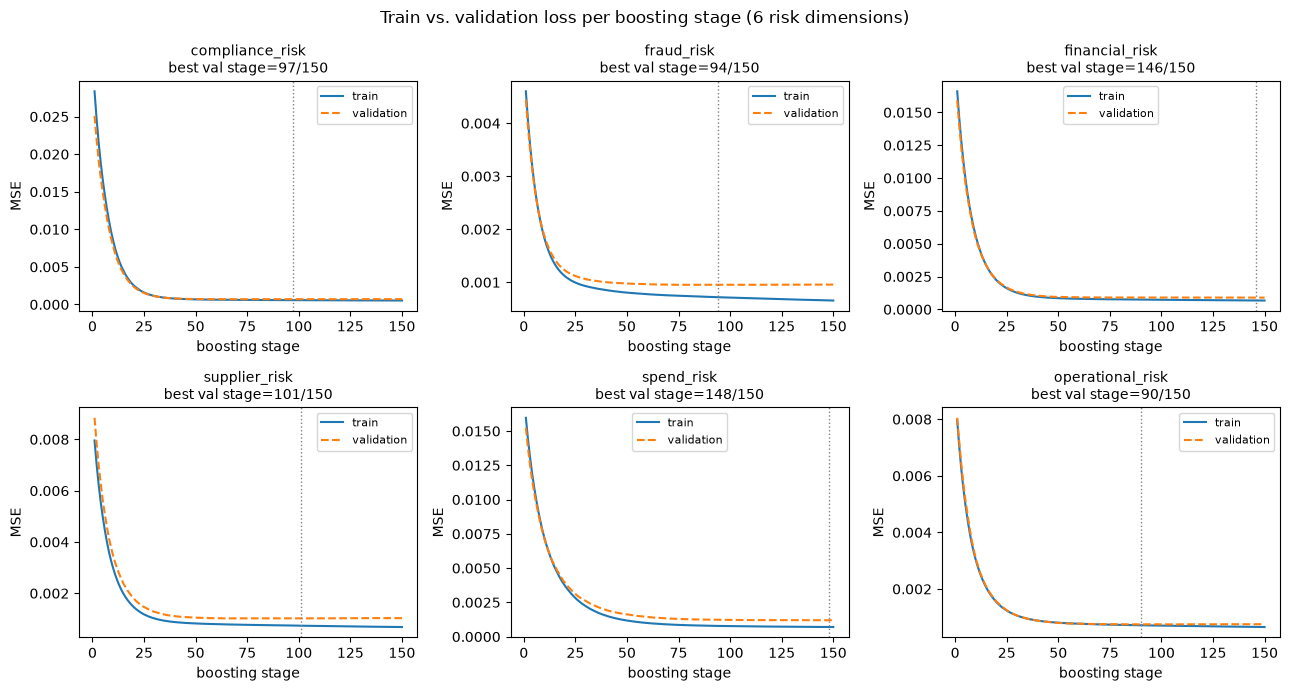

saved: results/learning_curves.png


In [18]:
n_stages = model.estimators_[0].n_estimators
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
learning_curves = {}
for i, (dim, est) in enumerate(zip(RISK_DIMENSIONS, model.estimators_)):
    train_mse = np.array([mean_squared_error(y_train[:, i], pred) for pred in est.staged_predict(X_train)])
    val_mse = np.array([mean_squared_error(y_val[:, i], pred) for pred in est.staged_predict(X_val)])
    learning_curves[dim] = {"train_mse": train_mse.tolist(), "validation_mse": val_mse.tolist()}

    ax = axes.flat[i]
    stages = np.arange(1, n_stages + 1)
    ax.plot(stages, train_mse, label="train", color="tab:blue")
    ax.plot(stages, val_mse, label="validation", color="tab:orange", linestyle="--")
    best_stage = int(np.argmin(val_mse)) + 1
    ax.axvline(best_stage, color="gray", linestyle=":", linewidth=1)
    ax.set_title(f"{dim}\nbest val stage={best_stage}/{n_stages}", fontsize=10)
    ax.set_xlabel("boosting stage"); ax.set_ylabel("MSE")
    ax.legend(fontsize=8)
fig.suptitle("Train vs. validation loss per boosting stage (6 risk dimensions)")
fig.tight_layout()
lc_path = RESULTS_DIR / "learning_curves.png"
fig.savefig(lc_path, dpi=140)
plt.show()
print("saved:", lc_path.relative_to(SERVICE_ROOT))


**Reading these:** every dimension shows the classic diminishing-returns boosting
shape — steep early drop, then a long flat tail — and train/validation track each other
closely the whole way, with only a small, stable gap. The dotted vertical line marks the
stage where validation loss was lowest; a few dimensions (`financial_risk` at 146,
`spend_risk` at 148) use almost the full 150 stages, while others (`operational_risk` at
90, `fraud_risk` at 94) would technically do marginally better stopped earlier — but the
gap past that point is tiny (look at the y-axis scale) and validation loss never turns
sharply upward anywhere, which is what real overfitting would look like. `n_estimators=150`
is a reasonable fixed choice here; early stopping would be a refinement, not a fix for a
problem that's visibly present.

### ROC / AUC

A regression model's six continuous 0–1 outputs aren't classifier probabilities, so ROC/AUC
needs a binary question to answer first. Two are used here, both on the untouched **test**
set:

1. **Per-dimension:** for each of the six dimensions independently, "is this vendor in the
   riskiest 10% of vendors *for this dimension*?" — threshold fit on train's own
   distribution (`np.quantile(y_train, 0.90)`), applied unchanged to test. A flat 0.67 cutoff
   was tried first and doesn't work per-dimension: `fraud_risk` and `supplier_risk` never
   actually reach 0.67 anywhere in the 4,000-row pool (their formulas are weighted to cap out
   lower) — 0.67 is calibrated for the *blended overall* score, not for any individual raw
   dimension, so it produced zero positive examples for those two and ROC needs both classes
   present. Each dimension's own top decile fixes that.
2. **Production decision:** "is this vendor's blended `overall_risk` in the true 'high'
   band?" against the model's predicted `overall_risk` — this is the actual threshold
   `approval_workflow` acts on, so it's the curve that matters most operationally.


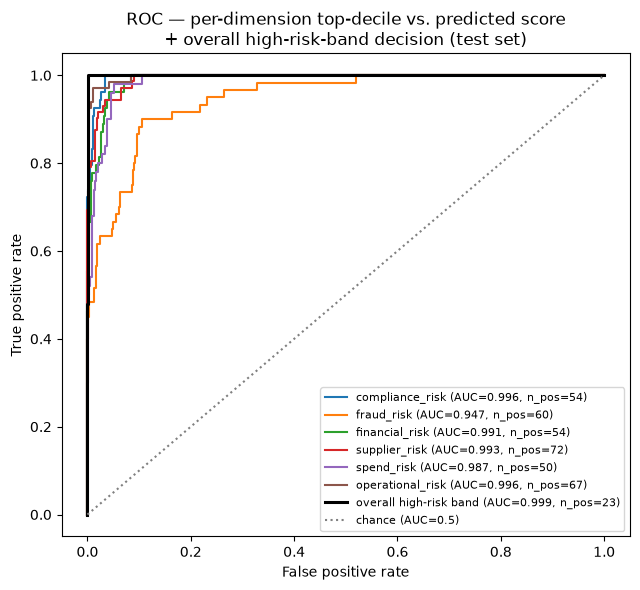

saved: results/roc_auc.png


,AUC,n_positive
compliance_risk,0.996107,54.0
fraud_risk,0.947073,60.0
financial_risk,0.990555,54.0
supplier_risk,0.992596,72.0
spend_risk,0.987005,50.0
operational_risk,0.996339,67.0
overall_high_risk_band,0.999097,23.0


In [19]:
preds_test = np.clip(model.predict(X_test), 0.0, 1.0)
fig, ax = plt.subplots(figsize=(6.5, 6))
roc_data = {}
for i, dim in enumerate(RISK_DIMENSIONS):
    threshold = float(np.quantile(y_train[:, i], 0.90))
    y_true_bin = (y_test[:, i] > threshold).astype(int)
    fpr, tpr, _ = roc_curve(y_true_bin, preds_test[:, i])
    auc = roc_auc_score(y_true_bin, preds_test[:, i])
    roc_data[dim] = {"fpr": fpr.tolist(), "tpr": tpr.tolist(), "auc": float(auc),
                      "threshold": threshold, "positive_count": int(y_true_bin.sum())}
    ax.plot(fpr, tpr, label=f"{dim} (AUC={auc:.3f}, n_pos={int(y_true_bin.sum())})")

true_band_test = compute_bands(y_test, LOW_MAX, MEDIUM_MAX)
pred_overall_test = compute_overall(preds_test, LOW_MAX, MEDIUM_MAX)
y_true_high = (true_band_test == "high").astype(int)
fpr_o, tpr_o, _ = roc_curve(y_true_high, pred_overall_test)
auc_o = roc_auc_score(y_true_high, pred_overall_test)
roc_data["overall_high_risk_band"] = {"fpr": fpr_o.tolist(), "tpr": tpr_o.tolist(), "auc": float(auc_o),
                                       "positive_count": int(y_true_high.sum())}
ax.plot(fpr_o, tpr_o, label=f"overall high-risk band (AUC={auc_o:.3f}, n_pos={int(y_true_high.sum())})",
        color="black", linewidth=2.2)

ax.plot([0, 1], [0, 1], linestyle=":", color="gray", label="chance (AUC=0.5)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC \u2014 per-dimension top-decile vs. predicted score\n+ overall high-risk-band decision (test set)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
roc_path = RESULTS_DIR / "roc_auc.png"
fig.savefig(roc_path, dpi=140)
plt.show()
print("saved:", roc_path.relative_to(SERVICE_ROOT))
pd.DataFrame({k: {"AUC": v["auc"], "n_positive": v["positive_count"]} for k, v in roc_data.items()}).T


**Reading this:** `fraud_risk` (AUC 0.947) is visibly the weakest curve — consistent
with it being the dimension built from the most, and weakest-correlated, individual
signals (watchlist hit, fraud-flag rate, mean fraud score, duplicate rate, round-amount
rate all blended together). Every other dimension sits at 0.98–1.00, and the curve that
matters most operationally — the overall high-risk-band decision — is essentially in the
top-left corner (AUC 0.999). None of this should be mistaken for evidence the *real-world*
model will be this clean; it's expected here because the labels were generated by a
formula close to linear in these same features, which is an easy pattern for a model to
learn near-perfectly. Real historical outcomes will almost certainly produce lower, more
realistic AUCs — that's not a regression, it's the synthetic-data ceiling coming down to
where real noise actually lives.

### Update the validation report with these results


In [20]:
report = json.loads((RESULTS_DIR / "validation_report.json").read_text())
report["learning_curves"] = learning_curves
report["roc_auc"] = roc_data
(RESULTS_DIR / "validation_report.json").write_text(json.dumps(report, indent=2))
print("updated:", (RESULTS_DIR / "validation_report.json").relative_to(SERVICE_ROOT))


updated: results/validation_report.json


## 7. Summary

| Artifact | Path | Produced by |
|---|---|---|
| Full synthetic pool | `data/vendor_risk_training_data.csv` | `generate_training_data()` (Section 1) |
| Train / validation / test splits | `data/vendor_risk_{train,validation,test}.csv` | `generate_train_val_test()` (Section 5) |
| Trained model (train-split only) | `models/vendor_risk_model.pkl` | fit in Section 5, joblib-pickled |
| Model card | `models/vendor_risk_model_card.json` | input/output schema + which split trained/validated/tested it |
| Ad hoc train/test metrics | `results/training_metrics.json` | Section 2's original 80/20 split |
| **Full validation report** | `results/validation_report.json` | Sections 5–6 — per-split/per-dimension MAE/RMSE/R², band confusion matrix, learning curves, ROC/AUC |
| **Confusion matrix plot** | `results/confusion_matrix_test.png` | Section 5 |
| **Learning curves plot** | `results/learning_curves.png` | Section 6 — train vs. validation MSE per boosting stage |
| **ROC/AUC plot** | `results/roc_auc.png` | Section 6 |
| Anomaly demo invoices | `data/anomaly_demo_vendor_invoices.csv` | synthetic, for illustration |
| Anomaly demo results | `results/anomaly_demo_results.json` | `app.anomaly.detect()` |

**What changed in the deployed system vs. this notebook:** nothing in `mlflow_utils.py` or
the live `/risk/assess` path was touched. The service still calls `train_model()`, which
still uses its own internal 80/20 split, on every fresh MLflow instance's first boot. This
notebook's train/validation/test split, `evaluate_model()`, and `compute_bands()`/
`compute_overall()` are new, reusable functions added to `app/model.py` — real code, not
notebook-only scratch work — but wiring them into the live training/registration path (so
MLflow itself logs validation metrics and these plots, not just a single train/test number)
is a follow-up, not something this notebook did on its own.